Running 500-trial Monte Carlo uncertainty propagation...

 MONTE CARLO UNCERTAINTY RESULTS
Input Tracking Noise Assumed: ±5.0 mm
Flight Time: 0.3976 ± 0.0020 s
Goal Width (Y):    3.108 ± 0.056 m
Goal Height (Z):   1.619 ± 0.055 m
95% Confidence Interval Y: [2.998, 3.217] m
95% Confidence Interval Z: [1.512, 1.726] m


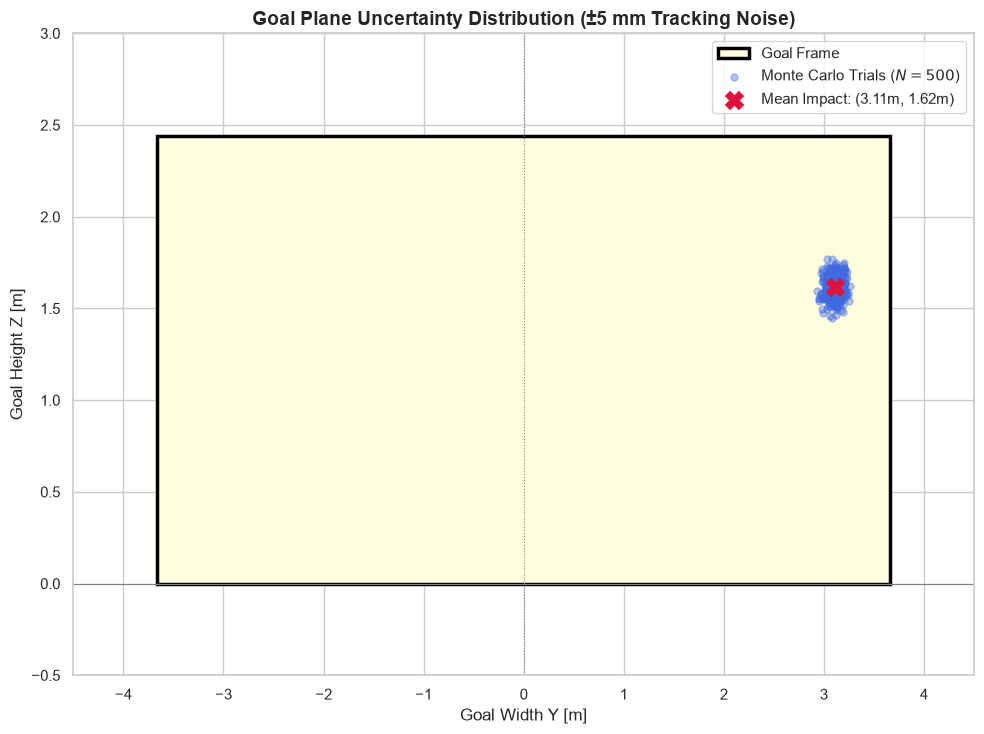

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import seaborn as sns

sns.set_theme(style="whitegrid")

# --- Physical Constants & Setup ---
m = 0.43
r = 0.11
A = np.pi * r**2
g = 9.81
altitude = 1400.0  # Kathmandu Valley
mu = 1.81e-5
omega = np.array([5.0, 10.0, 32.0])

# Base observed points
r0_base = np.array([0.0, 0.0, 0.11])
r1_base = np.array([1.50, 0.45, 0.44])
r2_base = np.array([2.96, 0.86, 0.74])

# Measurement noise standard deviation (+/- 5 mm tracking error)
sigma_spatial = 0.005

# Aerodynamic functions
def get_Cd(v_mag):
    v_crit = 18.0
    return 0.42 - (0.42 - 0.20) / (1.0 + np.exp(-0.5 * (v_mag - v_crit)))

def get_Cl(v_mag, omega_mag):
    if v_mag < 0.1 or omega_mag < 0.1:
        return 0.0
    return 0.18 * np.tanh(2.0 * (omega_mag * r) / v_mag)

def ode_system(t, state):
    x, y, z, vx, vy, vz = state
    v = np.array([vx, vy, vz])
    v_mag = np.linalg.norm(v)
    omega_mag = np.linalg.norm(omega)
    
    current_rho = 1.225 * np.exp(-max(0.0, altitude + z) / 8450.0)
    Cd = get_Cd(v_mag)
    a_drag = - (current_rho * A * Cd / (2.0 * m)) * v_mag * v
    
    if omega_mag > 0 and v_mag > 0.1:
        Cl = get_Cl(v_mag, omega_mag)
        a_magnus = (current_rho * A * r * Cl * omega_mag * v_mag / (2.0 * m)) * np.cross(omega / omega_mag, v / v_mag)
    else:
        a_magnus = np.zeros(3)
        
    a_grav = np.array([0.0, 0.0, -g])
    a_net = a_drag + a_magnus + a_grav
    return [vx, vy, vz, a_net[0], a_net[1], a_net[2]]

def reach_goal(t, state):
    return state[0] - 11.0
reach_goal.terminal = True
reach_goal.direction = 1

# --- Monte Carlo Loop ---
num_samples = 500
goal_y_samples = []
goal_z_samples = []
flight_times = []

print(f"Running {num_samples}-trial Monte Carlo uncertainty propagation...")

for _ in range(num_samples):
    r1_noisy = r1_base + np.random.normal(0, sigma_spatial, size=3)
    r2_noisy = r2_base + np.random.normal(0, sigma_spatial, size=3)
    v0_noisy = (r2_noisy - r1_noisy) / 0.05
    initial_state = [r0_base[0], r0_base[1], r0_base[2], v0_noisy[0], v0_noisy[1], v0_noisy[2]]

    sol = solve_ivp(
        ode_system, 
        t_span=(0.0, 1.0), 
        y0=initial_state, 
        events=reach_goal, 
        max_step=0.001
    )

    if len(sol.t_events[0]) > 0:
        t_hit = sol.t_events[0][0]
        final_state = sol.y[:, -1]
        goal_y_samples.append(final_state[1])
        goal_z_samples.append(final_state[2])
        flight_times.append(t_hit)

y_arr = np.array(goal_y_samples)
z_arr = np.array(goal_z_samples)
t_arr = np.array(flight_times)

# --- Statistical Analysis ---
y_mean, y_std = np.mean(y_arr), np.std(y_arr)
z_mean, z_std = np.mean(z_arr), np.std(z_arr)
t_mean, t_std = np.mean(t_arr), np.std(t_arr)

print("\n==========================================")
print(" MONTE CARLO UNCERTAINTY RESULTS")
print("==========================================")
print(f"Input Tracking Noise Assumed: ±{sigma_spatial*1000:.1f} mm")
print(f"Flight Time: {t_mean:.4f} ± {t_std:.4f} s")
print(f"Goal Width (Y):    {y_mean:.3f} ± {y_std:.3f} m")
print(f"Goal Height (Z):   {z_mean:.3f} ± {z_std:.3f} m")
print(f"95% Confidence Interval Y: [{y_mean - 1.96*y_std:.3f}, {y_mean + 1.96*y_std:.3f}] m")
print(f"95% Confidence Interval Z: [{z_mean - 1.96*z_std:.3f}, {z_mean + 1.96*z_std:.3f}] m")

# --- Visualization ---
fig, ax = plt.subplots(figsize=(10, 7.5))

goal_rect = plt.Rectangle((-3.66, 0.0), 7.32, 2.44, linewidth=2.5, edgecolor='black', facecolor='lightyellow', label='Goal Frame')
ax.add_patch(goal_rect)

ax.scatter(y_arr, z_arr, color='royalblue', alpha=0.4, s=25, label=f"Monte Carlo Trials ($N={num_samples}$)")
ax.scatter(y_mean, z_mean, color='crimson', s=160, marker='X', zorder=5, label=f"Mean Impact: ({y_mean:.2f}m, {z_mean:.2f}m)")

ax.set_title("Goal Plane Uncertainty Distribution (±5 mm Tracking Noise)", fontsize=14, fontweight='bold')
ax.set_xlabel("Goal Width Y [m]")
ax.set_ylabel("Goal Height Z [m]")
ax.set_xlim(-4.5, 4.5)
ax.set_ylim(-0.5, 3.0)
ax.axhline(0, color='gray', linewidth=0.8)
ax.axvline(0, color='gray', linewidth=0.8, linestyle=':')
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()